# Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score, accuracy_score, roc_curve, auc

In [ ]:
import sys
your_path = '/insert/your/path'
source_path = your_path + '/Project_Capone_Chisari/src'
dataset_path = your_path + '/Project_Capone_Chisari/'
history_path = your_path + '/Project_Capone_Chisari/histories/'
model_path = your_path + '/Project_Capone_Chisari/model/'
if source_path not in sys.path:
    sys.path.append(source_path)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Utils**

In [ ]:
from utils import early_stopping, reduce_lr, aggro_data_augmentation, data_augmentation, create_models_probs_dict
from function import plot_image_examples, get_class_weights, plot_training_history, save_history, load_history
from function import visualize_data_augmentation, plot_ensemble_val_loss, plot_confusion_matrix, compute_model_weights, ensemble_predict_weighted, find_best_threshold_f1
from function import plot_multiple_roc_curves, plot_multiple_pr_curves
from custom_model import CustomModel

# Dataset exploration

In [ ]:
dataset = np.load(dataset_path + "brain_tumor15.npz")
list(dataset.keys())
print("Keys in the dataset are: ", dataset.files)

Keys in the dataset are:  ['data', 'classes']


In [ ]:
dataset = np.load(dataset_path + "brain_tumor15.npz")
list(dataset.keys())
print("Keys in the dataset are: ", dataset.files)

X = dataset['data']
y = dataset['classes']
print("Shape of images: ", X.shape)
print("Shape of classes: ", y.shape)

class_counts = np.unique(y, return_counts=True)
print("Classes: ", class_counts[0])
print("Counts: ", class_counts[1])

# 1. Dividing the dataset into training (80%) and testing (20%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

# Val (20%) + Test (20%) dal temp
X_val, X_test, y_val, y_test = train_test_split( X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp )

#Normalizing data
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

Keys in the dataset are:  ['data', 'classes']
Shape of images:  (3762, 240, 240, 1)
Shape of classes:  (3762,)
Classes:  [0 1]
Counts:  [2079 1683]


In [ ]:
total_samples = len(X)
train_samples = len(X_train)
val_samples = len(X_val)
test_samples = len(X_test)

print(f"Total dataset: {total_samples} images")
print("-" * 30)
print(f"Training set: {train_samples} images ({train_samples/total_samples:.0%})")
print(f"Validation set: {val_samples} images ({val_samples/total_samples:.0%})")
print(f"Test set: {test_samples} images ({test_samples/total_samples:.0%})")

Total dataset: 3762 images
------------------------------
Training set: 2257 images (60%)
Validation set: 752 images (20%)
Test set: 753 images (20%)


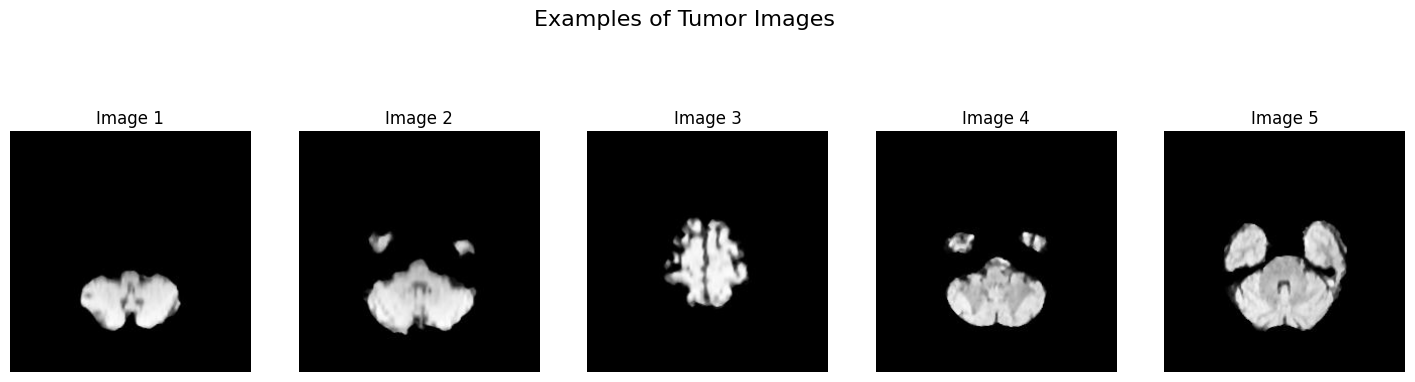

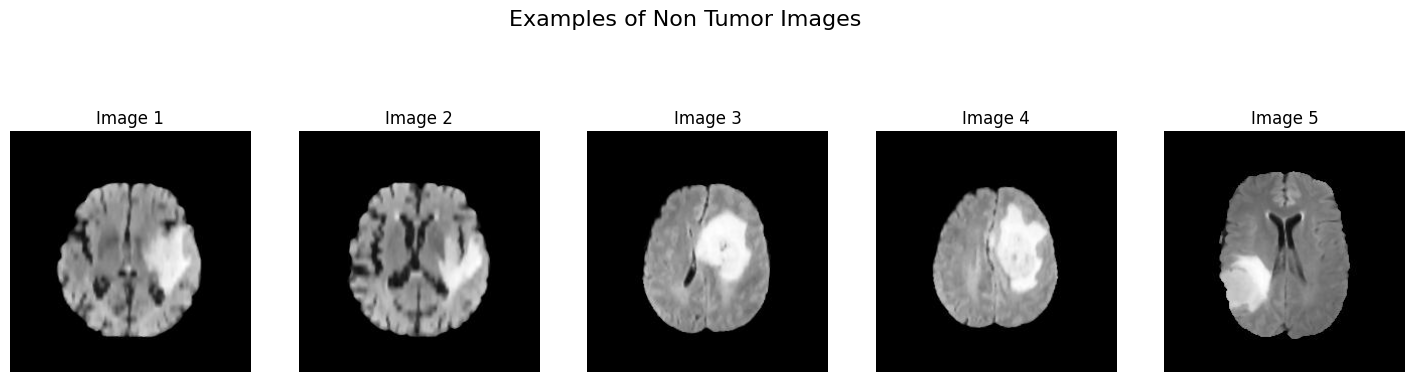

In [ ]:
plot_image_examples(X, y, 5)

# **Class Weights**

In [ ]:
class_weights_array = get_class_weights(y_train)
class_weights = dict(enumerate(class_weights_array))

print("Class Weights:", class_weights)

Class Weights: {0: np.float64(0.904971932638332), 1: np.float64(1.1173267326732674)}


# Seed

In [ ]:
tf.keras.utils.set_random_seed(73)
tf.config.experimental.enable_op_determinism()

# **Baseline Model**

In [ ]:
from models_params import baseline_model_params

In [ ]:
baseline_model = CustomModel(**baseline_model_params).build_model()
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 554)            │    31,910,954 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       284,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       246,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 448)            │       215,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 416)            │       186,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 384)            │       160,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 352)            │       135,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 320)            │       112,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 288)            │        92,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │        73,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 224)            │        57,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 192)            │        43,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 160)            │        30,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        20,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,579,243 (128.09 MB)

 Trainable params: 33,579,243 (128.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
baseline_model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics = ["accuracy"]
)

baseline_hist = baseline_model.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 20,
    validation_data = (X_val, y_val)
)

Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 55ms/step - accuracy: 0.6043 - loss: 0.6411 - val_accuracy: 0.7766 - val_loss: 0.5136
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.7800 - loss: 0.5172 - val_accuracy: 0.7832 - val_loss: 0.5154
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.7979 - loss: 0.4701 - val_accuracy: 0.7673 - val_loss: 0.5584
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.8094 - loss: 0.4597 - val_accuracy: 0.8005 - val_loss: 0.4412
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.8277 - loss: 0.4096 - val_accuracy: 0.8178 - val_loss: 0.4458
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.8277 - loss: 0.3894 - val_accuracy: 0.8364 - val_loss: 0.3621
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.8438 - loss: 0.4246 - val_accuracy: 0.8045 - val_loss: 0.4183
Epoch 8/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.8439 - loss: 0.3802 - val_accuracy: 0.8338 - v

In [ ]:
baseline_model.save(model_path + "baseline_model.keras")
save_history(baseline_hist, history_path, "history_baseline.npy")

In [ ]:
history_baseline = load_history(history_path, "history_baseline.npy")

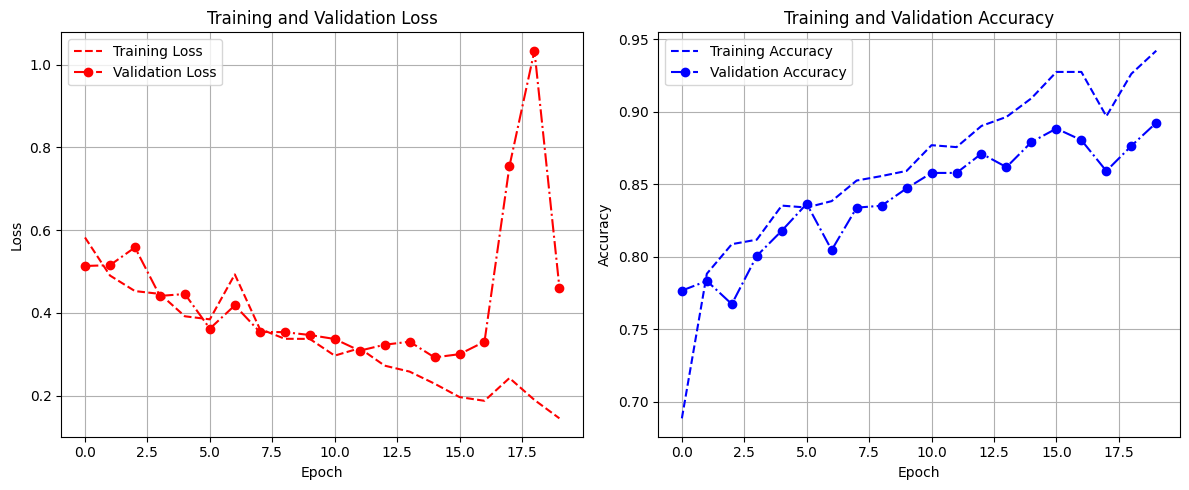

In [ ]:
plot_training_history(history_baseline)

##Dropout

In [ ]:
from models_params import bm_dropout_04_params, bm_dropout_03_params, bm_dropout_02_params

In [ ]:
bm_dropout_04 = CustomModel(**bm_dropout_04_params).build_model()
bm_dropout_04.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 554)            │    31,910,954 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 554)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 512)            │       284,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 480)            │       246,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 448)            │       215,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 416)            │       186,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 416)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 384)            │       160,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 352)            │       135,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 320)            │       112,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 288)            │        92,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 256)            │        73,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 224)            │        57,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 224)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 192)            │        43,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 192)            │             

 Total params: 33,579,243 (128.09 MB)

 Trainable params: 33,579,243 (128.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
bm_dropout_03 = CustomModel(**bm_dropout_03_params).build_model()
bm_dropout_03.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 554)            │    31,910,954 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 554)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 512)            │       284,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 480)            │       246,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 448)            │       215,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 416)            │       186,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 416)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 384)            │       160,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 352)            │       135,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 320)            │       112,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 288)            │        92,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 256)            │        73,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 224)            │        57,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 224)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 192)            │        43,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 192)            │             

 Total params: 33,579,243 (128.09 MB)

 Trainable params: 33,579,243 (128.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
bm_dropout_02 = CustomModel(**bm_dropout_02_params).build_model()
bm_dropout_02.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 554)            │    31,910,954 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 554)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 512)            │       284,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 480)            │       246,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_32 (Dropout)            │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 448)            │       215,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_33 (Dropout)            │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_52 (Dense)                │ (None, 416)            │       186,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_34 (Dropout)            │ (None, 416)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_53 (Dense)                │ (None, 384)            │       160,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_35 (Dropout)            │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 352)            │       135,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 320)            │       112,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_37 (Dropout)            │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 288)            │        92,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_38 (Dropout)            │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_57 (Dense)                │ (None, 256)            │        73,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_39 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_58 (Dense)                │ (None, 224)            │        57,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 224)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_59 (Dense)                │ (None, 192)            │        43,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_41 (Dropout)            │ (None, 192)            │             

 Total params: 33,579,243 (128.09 MB)

 Trainable params: 33,579,243 (128.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
bm_dropout_04.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics = ["accuracy"]
)

bm_dropout_04_hist = bm_dropout_04.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 20,
    validation_data = (X_val, y_val)
)

Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 36s 240ms/step - accuracy: 0.5004 - loss: 1.2282 - val_accuracy: 0.5532 - val_loss: 0.6916
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.5270 - loss: 0.7124 - val_accuracy: 0.5532 - val_loss: 0.6897
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.5263 - loss: 0.7046 - val_accuracy: 0.5532 - val_loss: 0.6884
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.5506 - loss: 0.6940 - val_accuracy: 0.5532 - val_loss: 0.6876
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5378 - loss: 0.6917 - val_accuracy: 0.5532 - val_loss: 0.6866
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.5939 - loss: 0.6842 - val_accuracy: 0.5532 - val_loss: 0.6814
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.6754 - loss: 0.6480 - val_accuracy: 0.5585 - val_loss: 0.6651
Epoch 8/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.7105 - loss: 0.6005 - val_accuracy: 0.5545 -

In [ ]:
bm_dropout_04.save(model_path + "bm_dropout_04.keras")
save_history(bm_dropout_04_hist, history_path, "bm_dropout_04_hist.npy")

In [ ]:
bm_dropout_03.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics = ["accuracy"]
)

bm_dropout_03_hist = bm_dropout_03.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 20,
    validation_data = (X_val, y_val)
)

Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 28s 191ms/step - accuracy: 0.5150 - loss: 0.8401 - val_accuracy: 0.5532 - val_loss: 0.6914
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5122 - loss: 0.7035 - val_accuracy: 0.5532 - val_loss: 0.6860
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.5527 - loss: 0.6208 - val_accuracy: 0.7872 - val_loss: 0.5354
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.7538 - loss: 0.5620 - val_accuracy: 0.7846 - val_loss: 0.5243
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.7737 - loss: 0.5220 - val_accuracy: 0.7859 - val_loss: 0.4856
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.7614 - loss: 0.5294 - val_accuracy: 0.8019 - val_loss: 0.4938
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.7744 - loss: 0.4983 - val_accuracy: 0.7101 - val_loss: 0.5698
Epoch 8/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.7865 - loss: 0.4853 - val_accuracy: 0.7846 -

In [ ]:
bm_dropout_03.save(model_path + "bm_dropout_03.keras")
save_history(bm_dropout_03_hist, history_path, "bm_dropout_03_hist.npy")

In [ ]:
bm_dropout_02.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics = ["accuracy"]
)

bm_dropout_02_hist = bm_dropout_02.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 20,
    validation_data = (X_val, y_val)
)

Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 44s 256ms/step - accuracy: 0.5039 - loss: 0.7406 - val_accuracy: 0.5532 - val_loss: 0.5757
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.6364 - loss: 0.5882 - val_accuracy: 0.7660 - val_loss: 0.5320
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7275 - loss: 0.5859 - val_accuracy: 0.7766 - val_loss: 0.4896
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.7768 - loss: 0.5248 - val_accuracy: 0.7952 - val_loss: 0.4595
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7840 - loss: 0.4977 - val_accuracy: 0.7886 - val_loss: 0.4882
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.7821 - loss: 0.4549 - val_accuracy: 0.8019 - val_loss: 0.4259
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.7914 - loss: 0.4696 - val_accuracy: 0.8138 - val_loss: 0.4492
Epoch 8/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8082 - loss: 0.4450 - val_accuracy: 0.8005 -

In [ ]:
bm_dropout_02.save(model_path + "bm_dropout_02.keras")
save_history(bm_dropout_02_hist, history_path, "bm_dropout_02_hist.npy")

In [ ]:
bm_dropout_04_hist=load_history(history_path, "bm_dropout_04_hist.npy")
bm_dropout_03_hist=load_history(history_path, "bm_dropout_03_hist.npy")
bm_dropout_02_hist=load_history(history_path, "bm_dropout_02_hist.npy")

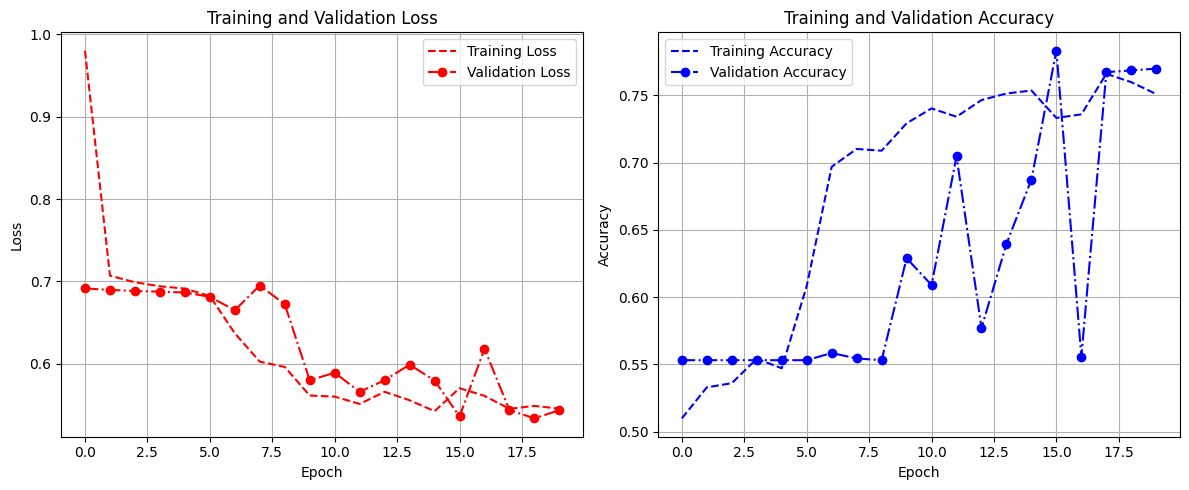

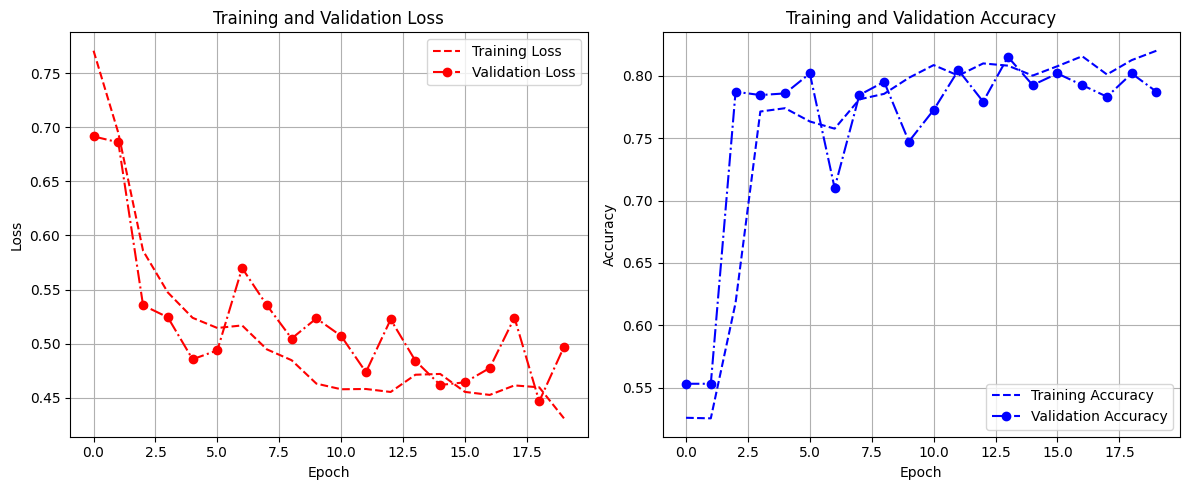

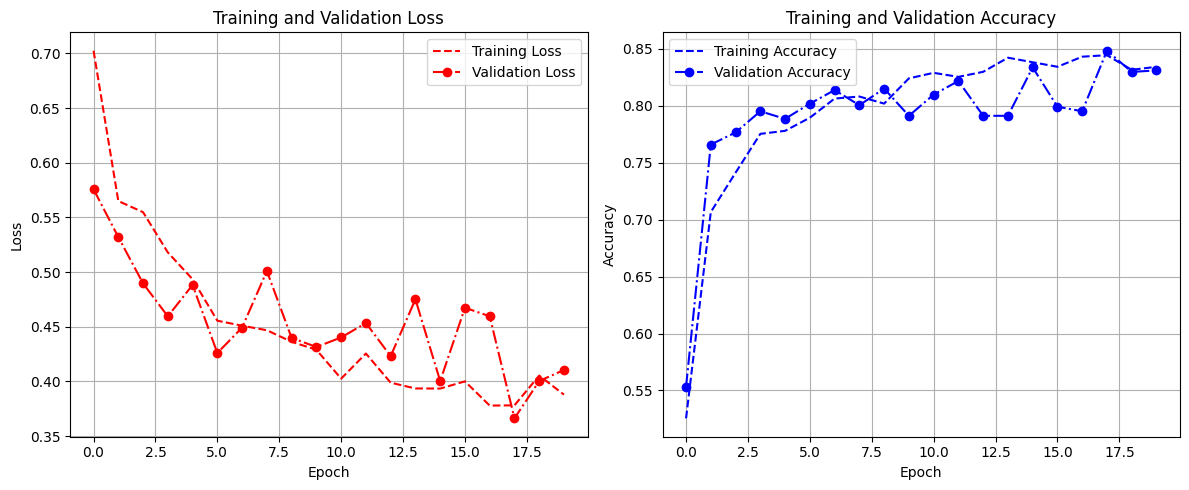

In [ ]:
plot_training_history(bm_dropout_04_hist)
plot_training_history(bm_dropout_03_hist)
plot_training_history(bm_dropout_02_hist)

## Data Augmentation

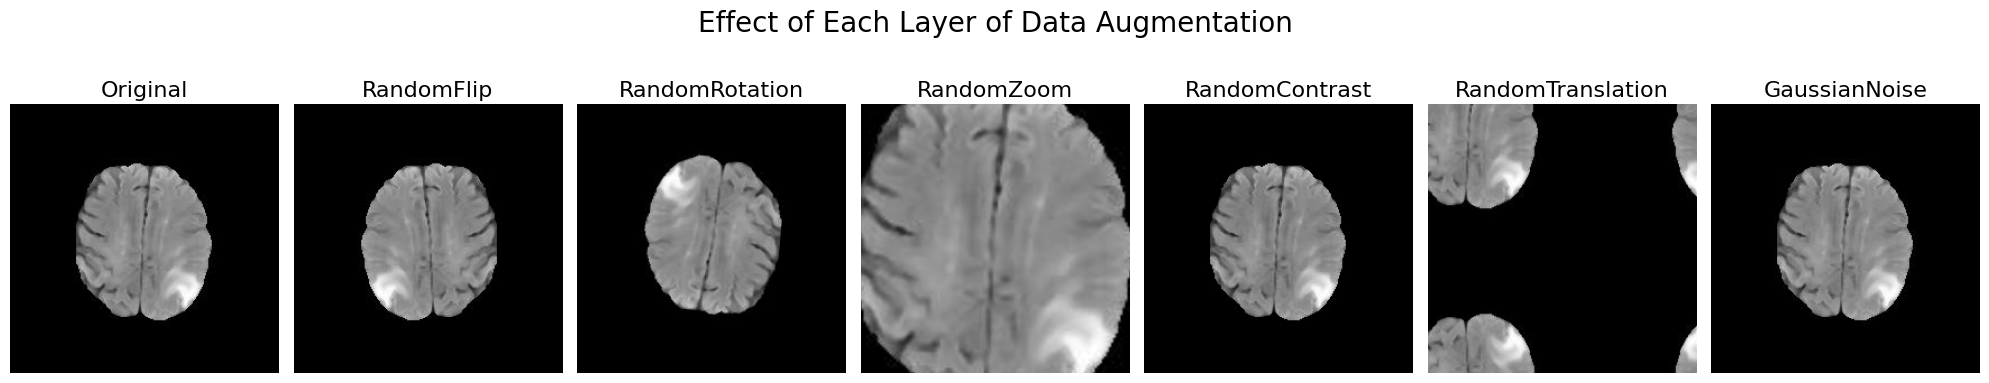

In [ ]:
visualize_data_augmentation(aggro_data_augmentation, X_train[0])

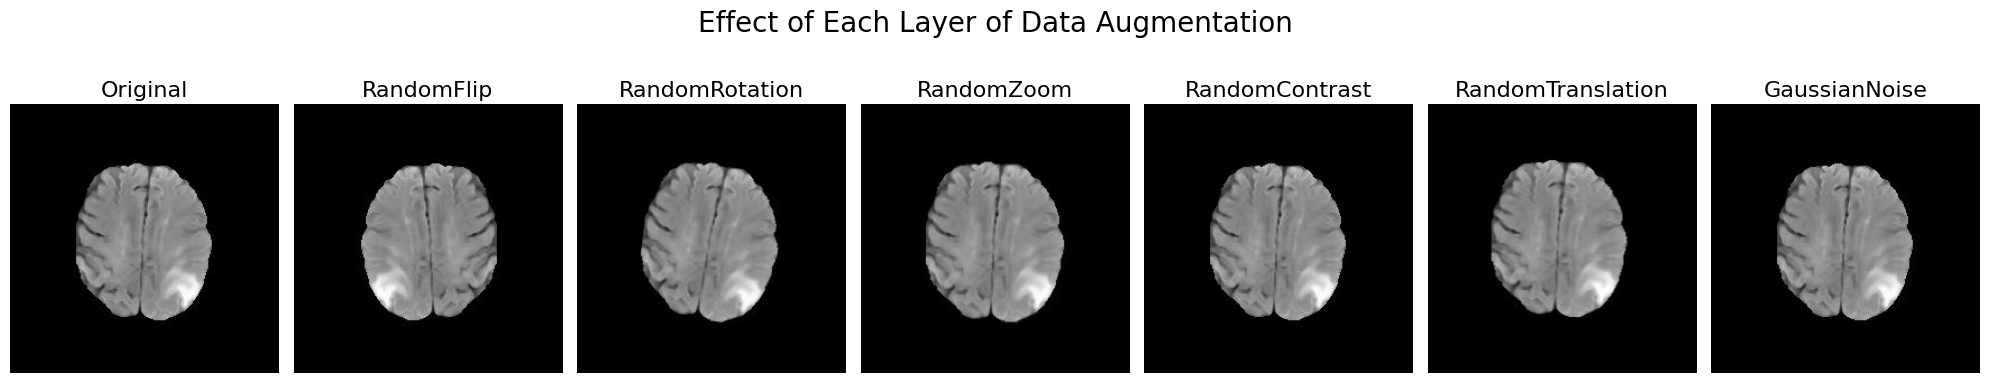

In [ ]:
visualize_data_augmentation(data_augmentation, X_train[0])

In [ ]:
from models_params import aggr_data_augmentation_params, data_augmentation_params

In [ ]:
aggro_data_augmentation_model = CustomModel(**aggr_data_augmentation_params).build_model()
aggro_data_augmentation_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aggro_data_augmentation         │ (None, 240, 240, 1)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 554)            │    31,910,954 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 554)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       284,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       246,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 448)            │       215,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 416)            │       186,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 416)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 384)            │       160,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 352)            │       135,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 320)            │       112,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 288)            │        92,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │        73,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 224)            │        57,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 224)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 33,579,243 (128.09 MB)

 Trainable params: 33,579,243 (128.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
aggro_data_augmentation_model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics = ["accuracy"]
)

aggro_data_augmentation_hist = aggro_data_augmentation_model.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 20,
    validation_data = (X_val, y_val)
)

Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 16s 50ms/step - accuracy: 0.5430 - loss: 0.7390 - val_accuracy: 0.5532 - val_loss: 0.6901
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.5235 - loss: 0.6930 - val_accuracy: 0.5532 - val_loss: 0.6878
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.5445 - loss: 0.6922 - val_accuracy: 0.5532 - val_loss: 0.6869
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.5454 - loss: 0.6894 - val_accuracy: 0.5532 - val_loss: 0.6892
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.5153 - loss: 0.6948 - val_accuracy: 0.5532 - val_loss: 0.6803
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.5418 - loss: 0.6861 - val_accuracy: 0.5532 - val_loss: 0.6896
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.5388 - loss: 0.6874 - val_accuracy: 0.5532 - val_loss: 0.6898
Epoch 8/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.5407 - loss: 0.6802 - val_accuracy: 0.5532 - 

In [ ]:
aggro_data_augmentation_model.save(model_path + "aggro_data_augmentation_model.keras")
save_history(aggro_data_augmentation_hist, history_path, "aggro_data_augmentation_hist.npy")

In [ ]:
data_augmentation_model = CustomModel(**data_augmentation_params).build_model()
data_augmentation_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 240, 240, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 554)            │    31,910,954 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 554)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 512)            │       284,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 480)            │       246,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 448)            │       215,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 416)            │       186,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 416)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 384)            │       160,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 352)            │       135,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 320)            │       112,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 288)            │        92,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 288)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 256)            │        73,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 224)            │        57,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 224)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 192)            │        43,20

 Total params: 33,579,243 (128.09 MB)

 Trainable params: 33,579,243 (128.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
data_augmentation_model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics = ["accuracy"]
)

data_augmentation_hist = data_augmentation_model.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 20,
    validation_data = (X_val, y_val)
)

Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - accuracy: 0.5143 - loss: 0.7491 - val_accuracy: 0.5532 - val_loss: 0.6884
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.6591 - loss: 0.6682 - val_accuracy: 0.7540 - val_loss: 0.5936
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.6741 - loss: 0.6181 - val_accuracy: 0.7713 - val_loss: 0.5860
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.6833 - loss: 0.6072 - val_accuracy: 0.7606 - val_loss: 0.5521
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.7515 - loss: 0.5636 - val_accuracy: 0.7793 - val_loss: 0.5316
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.7514 - loss: 0.5564 - val_accuracy: 0.7793 - val_loss: 0.6058
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.7476 - loss: 0.5725 - val_accuracy: 0.7420 - val_loss: 0.5807
Epoch 8/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.7538 - loss: 0.5810 - val_accuracy: 0.7846 - 

In [ ]:
data_augmentation_model.save(model_path + "data_augmentation_model.keras")
save_history(data_augmentation_hist, history_path, "data_augmentation_hist.npy")

## ReduceLearningRateOnPlateau

In [ ]:
data_augmentation_lr02_model = CustomModel(**data_augmentation_params).build_model()
data_augmentation_lr03_model = CustomModel(**data_augmentation_params).build_model()
data_augmentation_lr04_model = CustomModel(**data_augmentation_params).build_model()

In [ ]:
data_augmentation_lr02_model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics = ["accuracy"]
)

rlr02 = reduce_lr(0.2)

data_augmentation_lr02_hist = data_augmentation_lr02_model.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 20,
    validation_data = (X_val, y_val),
    callbacks=[rlr02, early_stopping]
)

Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 13s 54ms/step - accuracy: 0.5355 - loss: 0.7217 - val_accuracy: 0.5532 - val_loss: 0.6703 - learning_rate: 0.0010
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.5759 - loss: 0.6081 - val_accuracy: 0.7261 - val_loss: 0.6034 - learning_rate: 0.0010
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.7360 - loss: 0.5628 - val_accuracy: 0.7301 - val_loss: 0.5951 - learning_rate: 0.0010
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.7437 - loss: 0.5281 - val_accuracy: 0.7965 - val_loss: 0.4595 - learning_rate: 0.0010
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.7794 - loss: 0.5064 - val_accuracy: 0.7979 - val_loss: 0.5025 - learning_rate: 0.0010
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.7578 - loss: 0.5068 - val_accuracy: 0.7912 - val_loss: 0.4508 - learning_rate: 0.0010
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.7685 - loss: 0.4899 - val_ac

In [ ]:
data_augmentation_lr02_model.save(model_path + "data_augmentation_lr02_model.keras")
save_history(data_augmentation_lr02_hist, history_path, "data_augmentation_lr02_hist.npy")

In [ ]:
data_augmentation_lr03_model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics = ["accuracy"]
)

rlr03 = reduce_lr(0.3)

data_augmentation_lr03_hist = data_augmentation_lr03_model.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 20,
    validation_data = (X_val, y_val),
    callbacks=[rlr03, early_stopping]
)

Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 11s 73ms/step - accuracy: 0.5201 - loss: 0.7547 - val_accuracy: 0.5824 - val_loss: 0.6874 - learning_rate: 0.0010
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 55ms/step - accuracy: 0.6265 - loss: 0.6727 - val_accuracy: 0.7473 - val_loss: 0.5983 - learning_rate: 0.0010
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.7395 - loss: 0.6026 - val_accuracy: 0.7660 - val_loss: 0.5396 - learning_rate: 0.0010
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.7309 - loss: 0.5732 - val_accuracy: 0.7500 - val_loss: 0.5713 - learning_rate: 0.0010
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.7372 - loss: 0.5852 - val_accuracy: 0.7832 - val_loss: 0.5434 - learning_rate: 0.0010
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.7649 - loss: 0.5602 - val_accuracy: 0.7048 - val_loss: 0.5720 - learning_rate: 0.0010
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.7293 - loss: 0.5587 - val_ac

In [ ]:
data_augmentation_lr03_model.save(model_path + "data_augmentation_lr03_model.keras")
save_history(data_augmentation_lr03_hist, history_path, "data_augmentation_lr03_hist.npy")

In [ ]:
data_augmentation_lr04_model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics = ["accuracy"]
)

rlr04 = reduce_lr(0.4)

data_augmentation_lr04_hist = data_augmentation_lr04_model.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 20,
    validation_data = (X_val, y_val),
    callbacks=[rlr04, early_stopping]
)

Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 11s 63ms/step - accuracy: 0.5241 - loss: 0.7301 - val_accuracy: 0.5532 - val_loss: 0.5656 - learning_rate: 0.0010
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.6357 - loss: 0.5852 - val_accuracy: 0.7979 - val_loss: 0.5736 - learning_rate: 0.0010
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.7493 - loss: 0.5503 - val_accuracy: 0.7899 - val_loss: 0.4782 - learning_rate: 0.0010
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.7574 - loss: 0.5177 - val_accuracy: 0.7872 - val_loss: 0.4521 - learning_rate: 0.0010
Epoch 5/20
70/71 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.7659 - loss: 0.5105
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0004000000189989805.
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.7661 - loss: 0.5102 - val_accuracy: 0.7912 - val_loss: 0.4525 - learning_rate: 0.0010
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.7846 - loss: 0.4967 - val_acc

In [ ]:
data_augmentation_lr04_model.save(model_path + "data_augmentation_lr04_model.keras")
save_history(data_augmentation_lr04_hist, history_path, "data_augmentation_lr04_hist.npy")

In [ ]:
data_augmentation_lr02_hist = load_history(history_path, "data_augmentation_lr02_hist.npy")
data_augmentation_lr03_hist = load_history(history_path, "data_augmentation_lr03_hist.npy")
data_augmentation_lr04_hist = load_history(history_path, "data_augmentation_lr04_hist.npy")

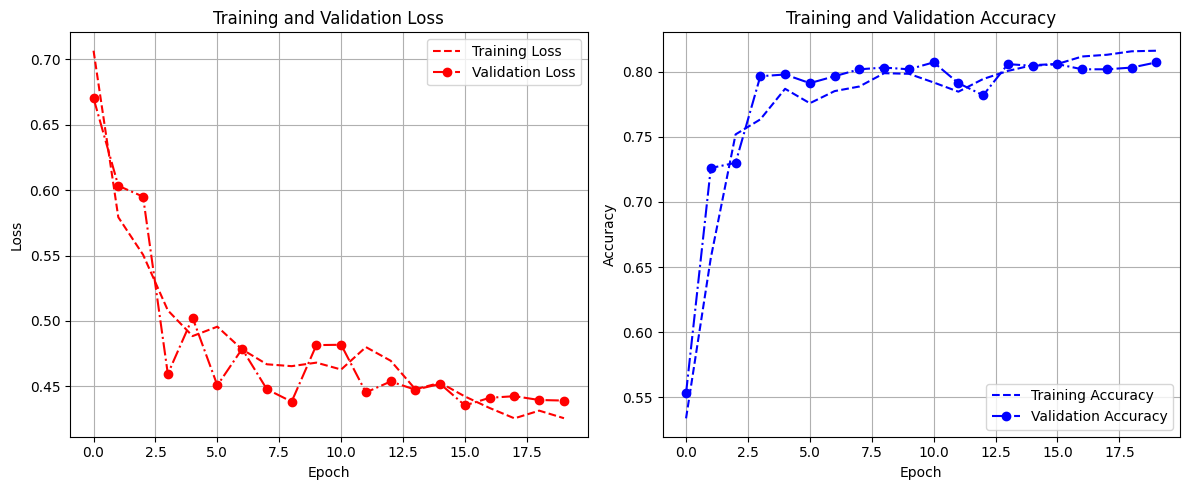

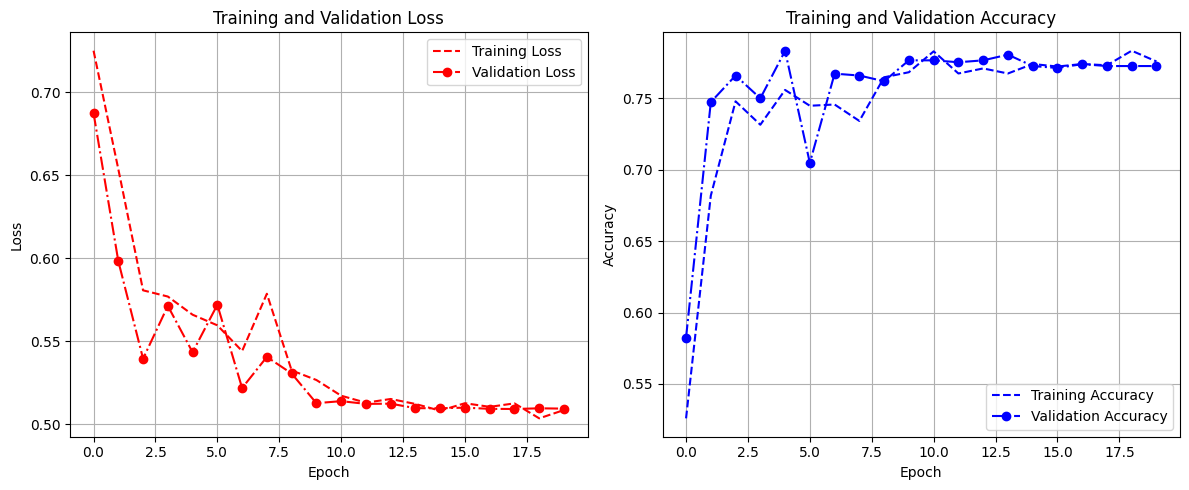

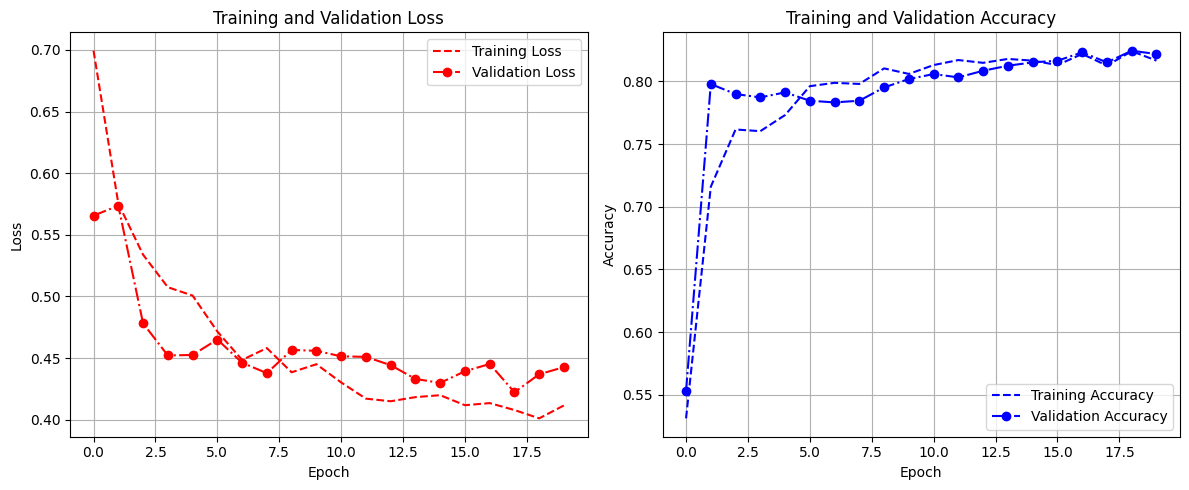

In [ ]:
plot_training_history(data_augmentation_lr02_hist)
plot_training_history(data_augmentation_lr03_hist)
plot_training_history(data_augmentation_lr04_hist)

# Convolution Layers

In [ ]:
from models_params import conv_params

In [ ]:
first_cnn_model = CustomModel(**conv_params).build_model()
first_cnn_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 240, 240, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 238, 238, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_6             │ (None, 119, 119, 32)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 117, 117, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_7             │ (None, 58, 58, 64)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_8             │ (None, 28, 28, 128)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_80 (Dense)                │ (None, 554)            │    55,595,562 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_75 (Dropout)            │ (None, 554)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_81 (Dense)                │ (None, 512)            │       284,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_76 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_82 (Dense)                │ (None, 480)            │       246,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_77 (Dropout)            │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_83 (Dense)                │ (None, 448)            │       215,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_78 (Dropout)            │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_84 (Dense)                │ (None, 416)            │       186,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_79 (Dropout)            │ (None, 416)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_85 (Dense)                │ (None, 384)            │       160,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_80 (Dropout)            │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_86 (Dense)                │ (None, 352)            │       135,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_81 (Dropout)            │ (None, 352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_87 (Dense)                │ (None, 320)            │       112,960 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 57,356,523 (218.80 MB)

 Trainable params: 57,356,523 (218.80 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
first_cnn_model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics = ["accuracy"]
)

rlr = reduce_lr(0.3)

first_cnn_model_hist = first_cnn_model.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 100,
    validation_data = (X_val, y_val),
    callbacks=[rlr, early_stopping]
)

Epoch 1/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 16s 129ms/step - accuracy: 0.5513 - loss: 0.6712 - val_accuracy: 0.5452 - val_loss: 0.6857 - learning_rate: 0.0010
Epoch 2/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 116ms/step - accuracy: 0.6520 - loss: 0.6334 - val_accuracy: 0.7553 - val_loss: 0.4987 - learning_rate: 0.0010
Epoch 3/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 111ms/step - accuracy: 0.7777 - loss: 0.5130 - val_accuracy: 0.8072 - val_loss: 0.3987 - learning_rate: 0.0010
Epoch 4/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 112ms/step - accuracy: 0.7958 - loss: 0.4868 - val_accuracy: 0.8138 - val_loss: 0.3845 - learning_rate: 0.0010
Epoch 5/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 8s 116ms/step - accuracy: 0.7986 - loss: 0.4433 - val_accuracy: 0.8484 - val_loss: 0.3436 - learning_rate: 0.0010
Epoch 6/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 8s 106ms/step - accuracy: 0.8297 - loss: 0.4169 - val_accuracy: 0.8404 - val_loss: 0.3133 - learning_rate: 0.0010
Epoch 7/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 102ms/step - accuracy: 0.8479 - loss

In [ ]:
first_cnn_model.save(model_path + "first_cnn_model.keras")
save_history(first_cnn_model_hist, history_path, "first_cnn_model_hist.npy")

In [ ]:
first_cnn_model_hist = load_history(history_path, "first_cnn_model_hist.npy")

## Max Pooling vs Average Pooling

In [ ]:
from models_params import max_pooling_params

In [ ]:
max_pooling_model = CustomModel(**max_pooling_params).build_model()

In [ ]:
max_pooling_model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics = ["accuracy"]
)

rlr = reduce_lr(0.3)

max_pooling_model_hist = max_pooling_model.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 100,
    validation_data = (X_val, y_val),
    callbacks=[rlr, early_stopping]
)

Epoch 1/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 16s 134ms/step - accuracy: 0.5827 - loss: 0.6661 - val_accuracy: 0.5532 - val_loss: 0.6967 - learning_rate: 0.0010
Epoch 2/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 8s 116ms/step - accuracy: 0.5429 - loss: 0.6970 - val_accuracy: 0.5532 - val_loss: 0.6875 - learning_rate: 0.0010
Epoch 3/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 8s 112ms/step - accuracy: 0.5564 - loss: 0.6865 - val_accuracy: 0.6529 - val_loss: 0.6481 - learning_rate: 0.0010
Epoch 4/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - accuracy: 0.5471 - loss: 0.6936 - val_accuracy: 0.5532 - val_loss: 0.6863 - learning_rate: 0.0010
Epoch 5/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 11s 115ms/step - accuracy: 0.6529 - loss: 0.6462 - val_accuracy: 0.7766 - val_loss: 0.5557 - learning_rate: 0.0010
Epoch 6/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - accuracy: 0.6802 - loss: 0.6789 - val_accuracy: 0.7832 - val_loss: 0.4724 - learning_rate: 0.0010
Epoch 7/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 8s 108ms/step - accuracy: 0.7514 - loss: 

In [ ]:
max_pooling_model.save(model_path + "max_pooling_model.keras")
save_history(max_pooling_model_hist, history_path, "max_pooling_model_hist.npy")

In [ ]:
max_pooling_hist = load_history(history_path, "max_pooling_model_hist.npy")

Average Pooling


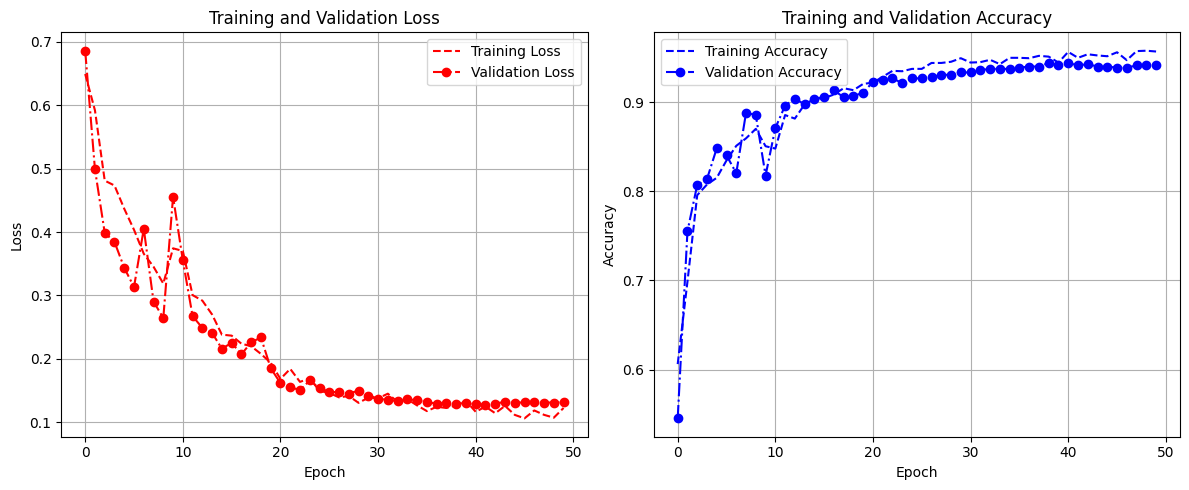

Max Pooling


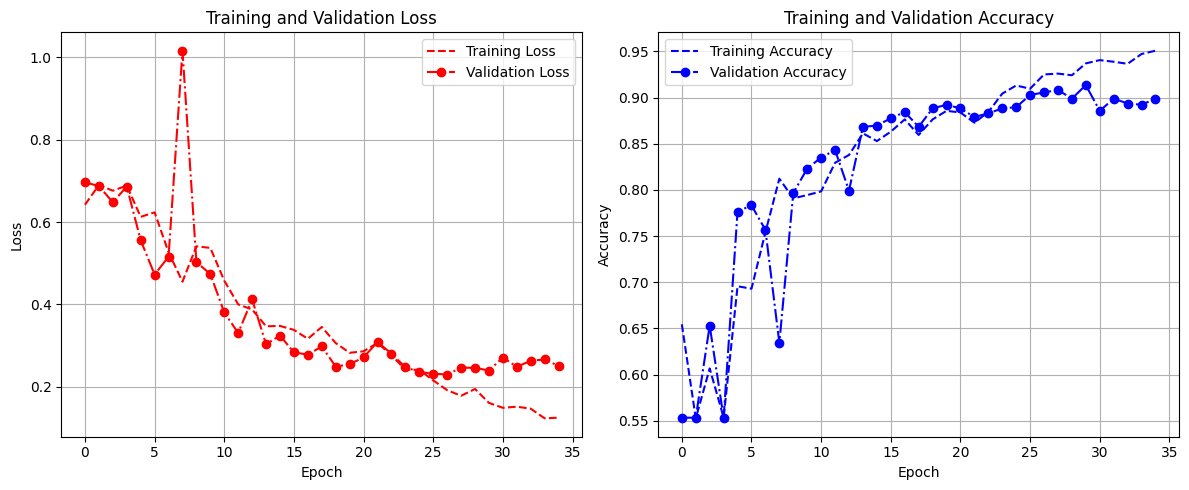

In [ ]:
print("Average Pooling")
plot_training_history(first_cnn_model_hist)
print("Max Pooling")
plot_training_history(max_pooling_model_hist)

# **Deep CNN**

In [ ]:
from models_params import deep_cnn_params

In [ ]:
deep_cnn = CustomModel(**deep_cnn_params).build_model()
deep_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 240, 240, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 238, 238, 64)   │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 119, 119, 64)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 117, 117, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 58, 58, 128)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 28, 28, 256)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (None, 13, 13, 512)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 192)            │        49,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,793,953 (90.77 MB)

 Trainable params: 23,793,953 (90.77 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
deep_cnn.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics = ["accuracy"]
)

rlr = reduce_lr(0.3)

deep_cnn_hist = deep_cnn.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 100,
    validation_data = (X_val, y_val),
    callbacks=[rlr, early_stopping]
)

In [ ]:
deep_cnn.save(model_path + "deep_cnn.keras")
save_history(deep_cnn_hist, history_path, "deep_cnn_hist.npy")

In [ ]:
deep_cnn_hist = load_history(history_path, "history_cnn9_c.npy")

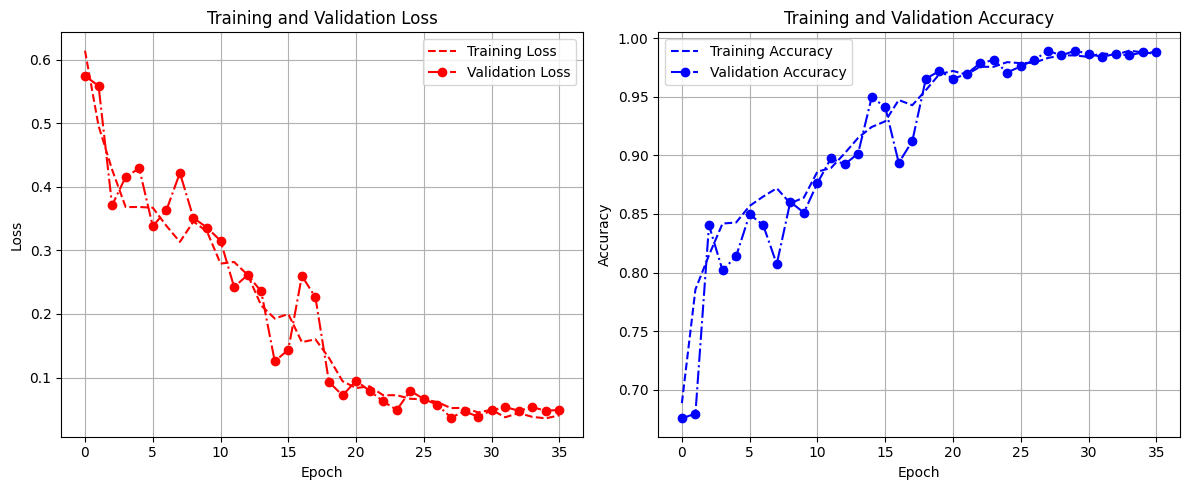

In [ ]:
plot_training_history(deep_cnn_hist)

# **VGG-Style**

## Optimizer: Adam

In [ ]:
from models_params import vgg_model_params

In [ ]:
vgg_adam = CustomModel(**vgg_model_params).build_model()
vgg_adam.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 240, 240, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 238, 238, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 236, 236, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 118, 118, 32)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 116, 116, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 114, 114, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 57, 57, 64)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 55, 55, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 53, 53, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_6             │ (None, 26, 26, 128)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 22, 22, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_7             │ (None, 11, 11, 256)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,147,105 (19.63 MB)

 Trainable params: 5,147,105 (19.63 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
vgg_adam.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    metrics = ["accuracy"]
)

rlr = reduce_lr(0.3)

vgg_adam_hist = vgg_adam.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 100,
    validation_data = (X_val, y_val),
    callbacks=[rlr, early_stopping]
)

In [ ]:
vgg_adam.save(model_path + "vgg_adam.keras")
save_history(vgg_adam_hist, history_path, "history_vgg_adam.npy")

In [ ]:
history_vgg_adam = load_history(history_path, "history_vgg_adam.npy")

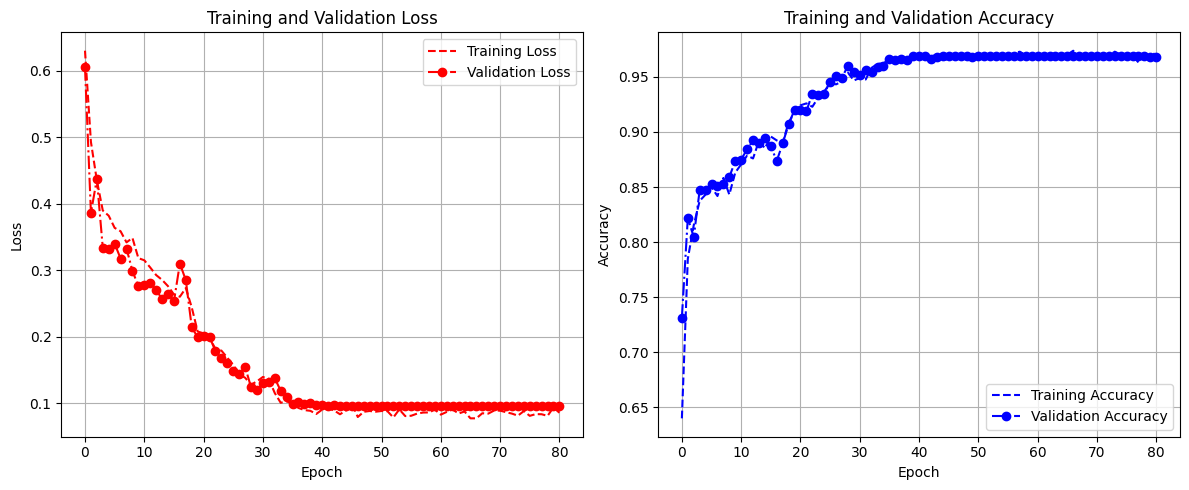

In [ ]:
plot_training_history(history_vgg_adam)

## Optimizer: SGD

### LR = 0.01

In [ ]:
vgg_sgd_001 = CustomModel(**vgg_model_params).build_model()
vgg_sgd_001.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 240, 240, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 238, 238, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 236, 236, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_8             │ (None, 118, 118, 32)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 116, 116, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 114, 114, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_9             │ (None, 57, 57, 64)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 55, 55, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 53, 53, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_10            │ (None, 26, 26, 128)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 22, 22, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_11            │ (None, 11, 11, 256)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,147,105 (19.63 MB)

 Trainable params: 5,147,105 (19.63 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from utils import optimizer_sgd

In [ ]:
vgg_sgd_001.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = optimizer_sgd(0.01, 0.9, False),
    metrics = ["accuracy"]
)

rlr = reduce_lr(0.3)

vgg_sgd_001_hist = vgg_sgd_001.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 100,
    validation_data = (X_val, y_val),
    callbacks=[rlr, early_stopping]
)

In [ ]:
vgg_sgd_001.save(model_path + "vgg_sgd_001.keras")
save_history(vgg_sgd_001_hist, history_path, "history_vgg_sgd_0_01.npy")

In [ ]:
history_vgg_sgd_001 = load_history(history_path, "history_vgg_sgd_0_01.npy")

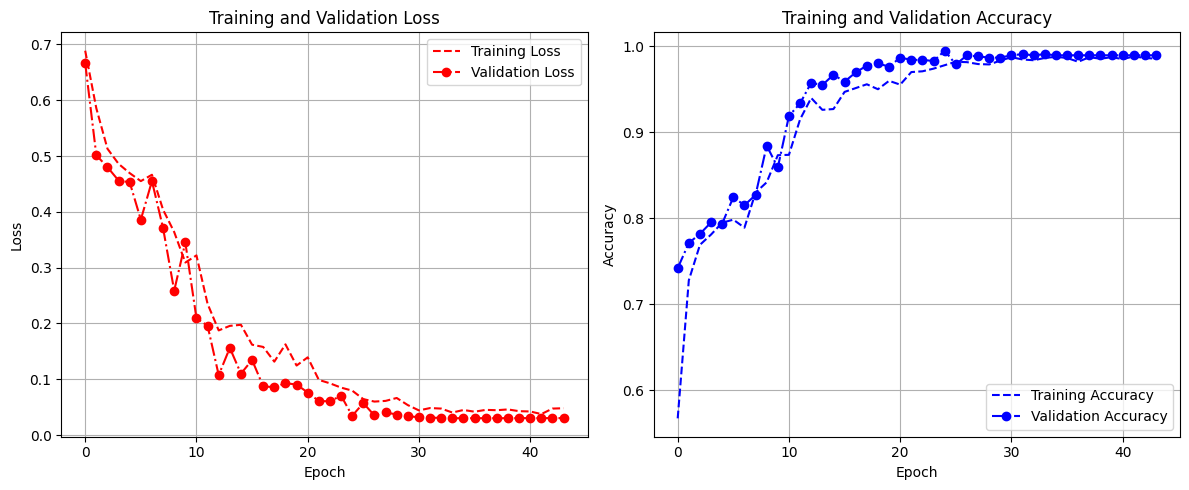

In [ ]:
plot_training_history(history_vgg_sgd_001)

### LR = 0.005

In [ ]:
vgg_sgd_0005 = CustomModel(**vgg_model_params).build_model()
vgg_sgd_0005.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 240, 240, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 238, 238, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 236, 236, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 118, 118, 32)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 116, 116, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 114, 114, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 57, 57, 64)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 55, 55, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 53, 53, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_6             │ (None, 26, 26, 128)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 22, 22, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_7             │ (None, 11, 11, 256)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,147,105 (19.63 MB)

 Trainable params: 5,147,105 (19.63 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
vgg_sgd_0005.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = optimizer_sgd(0.005, 0.9, False),
    metrics = ["accuracy"]
)

rlr = reduce_lr(0.3)

vgg_sgd_0005_hist = vgg_sgd_0005.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 100,
    validation_data = (X_val, y_val),
    callbacks=[rlr, early_stopping]
)

In [ ]:
vgg_sgd_0005.save(model_path + "vgg_sgd_0005.keras")
save_history(vgg_sgd_0005_hist, history_path, "history_vgg_sgd_0_005.npy")

In [ ]:
history_vgg_sgd_0005 = load_history(history_path, "history_vgg_sgd_0_005.npy")

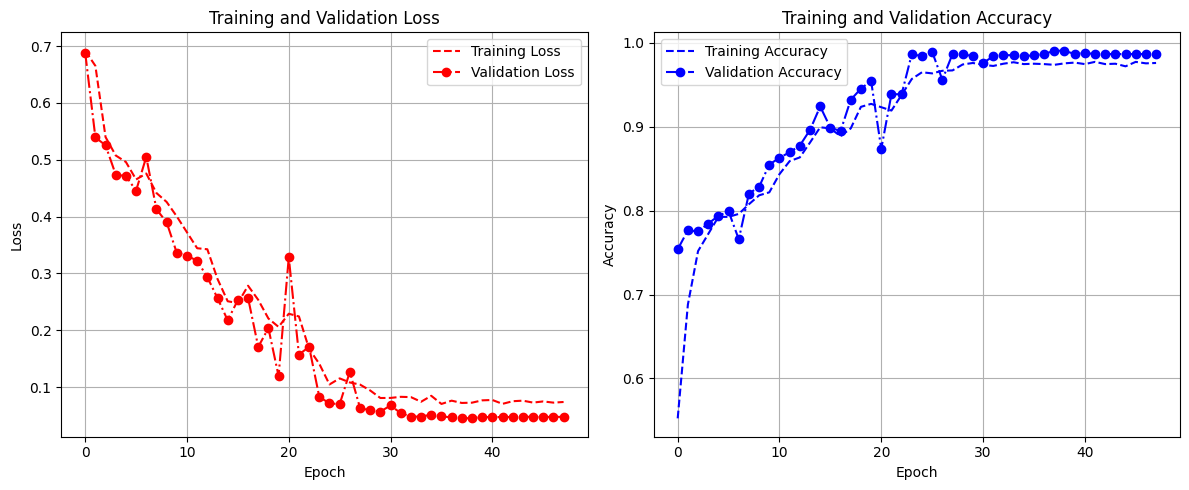

In [ ]:
plot_training_history(history_vgg_sgd_0005)

### LR = 0.001

In [ ]:
vgg_sgd_0001 = CustomModel(**vgg_model_params).build_model()
vgg_sgd_0001.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 240, 240, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 238, 238, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 236, 236, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 118, 118, 32)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 116, 116, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 114, 114, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 57, 57, 64)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 55, 55, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 53, 53, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_6             │ (None, 26, 26, 128)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 22, 22, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_7             │ (None, 11, 11, 256)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,147,105 (19.63 MB)

 Trainable params: 5,147,105 (19.63 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
vgg_sgd_0001.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = optimizer_sgd(0.001, 0.9, False),
    metrics = ["accuracy"]
)

rlr = reduce_lr(0.3)

vgg_sgd_0001_hist = vgg_sgd_0001.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 100,
    validation_data = (X_val, y_val),
    callbacks=[rlr, early_stopping]
)

In [ ]:
vgg_sgd_0001.save(model_path + "vgg_sgd_0001.keras")
save_history(vgg_sgd_0001_hist, history_path, "history_vgg_sgd_0_001.npy")

In [ ]:
history_vgg_sgd_0001 = load_history(history_path, "history_vgg_sgd_0_001.npy")

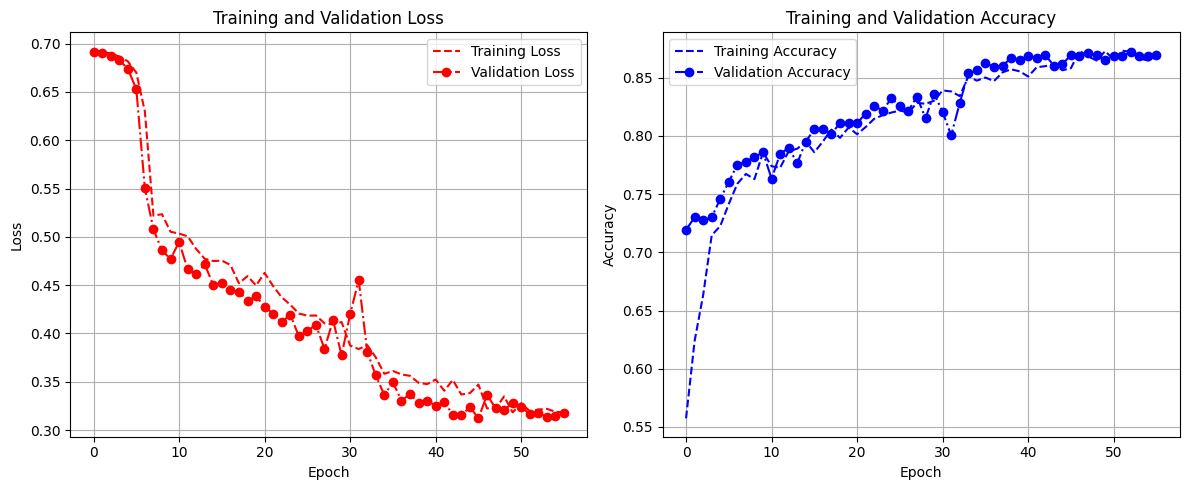

In [ ]:
plot_training_history(history_vgg_sgd_0001)

### LR = 0.01, Momentum = 0.95 + Nesterov Momentum

In [ ]:
vgg_sgd_001_nest = CustomModel(**vgg_model_params).build_model()
vgg_sgd_001_nest.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 240, 240, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 238, 238, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 236, 236, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 118, 118, 32)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 116, 116, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 114, 114, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 57, 57, 64)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 55, 55, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 53, 53, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_6             │ (None, 26, 26, 128)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 22, 22, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_7             │ (None, 11, 11, 256)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,147,105 (19.63 MB)

 Trainable params: 5,147,105 (19.63 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
vgg_sgd_001_nest.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = optimizer_sgd(0.01, 0.95, True),
    metrics = ["accuracy"]
)

rlr = reduce_lr(0.3)

vgg_sgd_001_nest_hist = vgg_sgd_001_nest.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 100,
    validation_data = (X_val, y_val),
    callbacks=[rlr, early_stopping]
)

In [ ]:
vgg_sgd_001_nest.save(model_path + "vgg_sgd_001_nest.keras")
save_history(vgg_sgd_001_nest_hist, history_path, "history_vgg_sgd_0_01_nest.npy")

In [ ]:
history_vgg_sgd_001_nest = load_history(history_path, "history_vgg_sgd_0_01_n.npy")

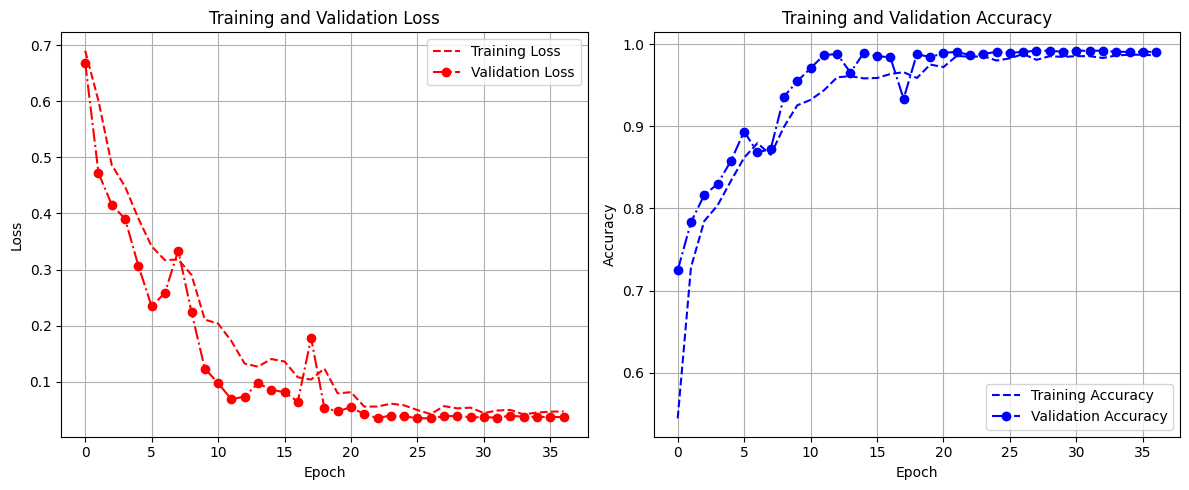

In [ ]:
plot_training_history(history_vgg_sgd_001_nest)

### LR = 0.005, Momentum = 0.95 + Nesterov Momentum

In [ ]:
vgg_sgd_0005_nest = CustomModel(**vgg_model_params).build_model()
vgg_sgd_0005_nest.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 240, 240, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 238, 238, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 236, 236, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 118, 118, 32)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 116, 116, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 114, 114, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 57, 57, 64)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 55, 55, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 53, 53, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_6             │ (None, 26, 26, 128)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 22, 22, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_7             │ (None, 11, 11, 256)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,147,105 (19.63 MB)

 Trainable params: 5,147,105 (19.63 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
vgg_sgd_0005_nest.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = optimizer_sgd(0.005, 0.95, True),
    metrics = ["accuracy"]
)

rlr = reduce_lr(0.3)

vgg_sgd_0005_nest_hist = vgg_sgd_0005_nest.fit(
    X_train, y_train,
    batch_size = 32,
    epochs = 100,
    validation_data = (X_val, y_val),
    callbacks=[rlr, early_stopping]
)

In [ ]:
vgg_sgd_0005_nest.save(model_path + "vgg_sgd_0005_nest.keras")
save_history(vgg_sgd_0005_nest_hist, history_path, "history_vgg_sgd_0_005_nest.npy")

In [ ]:
history_vgg_sgd_0005_nest = load_history(history_path, "history_vgg_sgd_0_005_n.npy")

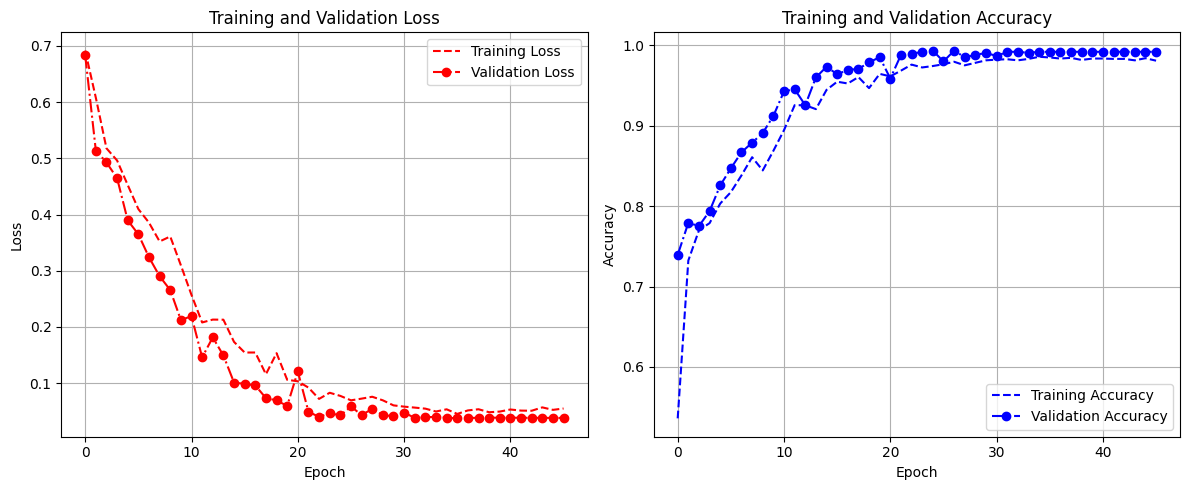

In [ ]:
plot_training_history(history_vgg_sgd_0005_nest)

# **Ensemble Learning**

In [ ]:
model_cnn1 = load_model(model_path + "cnn1.h5")
model_cnn2 = load_model(model_path + "cnn2.h5")
model_cnn3 = load_model(model_path + "cnn3.h5")
model_cnn4 = load_model(model_path + "cnn4.h5")
model_cnn5 = load_model(model_path + "cnn5.h5")
model_cnn6 = load_model(model_path + "cnn6.h5")
model_cnn7 = load_model(model_path + "cnn7.h5")
model_cnn8 = load_model(model_path + "cnn8.h5")
model_cnn9 = load_model(model_path + "cnn9.h5")
model_cnn10 = load_model(model_path + "cnn10.h5")

print('Evaluation of the Validation Models')
model_cnn1.evaluate(X_val, y_val)
model_cnn2.evaluate(X_val, y_val)
model_cnn3.evaluate(X_val, y_val)
model_cnn4.evaluate(X_val, y_val)
model_cnn5.evaluate(X_val, y_val)
model_cnn6.evaluate(X_val, y_val)
model_cnn7.evaluate(X_val, y_val)
model_cnn8.evaluate(X_val, y_val)
model_cnn9.evaluate(X_val, y_val)
model_cnn10.evaluate(X_val, y_val)

print('Evaluation of the Test Models')
model_cnn1.evaluate(X_test, y_test)
model_cnn2.evaluate(X_test, y_test)
model_cnn3.evaluate(X_test, y_test)
model_cnn4.evaluate(X_test, y_test)
model_cnn5.evaluate(X_test, y_test)
model_cnn6.evaluate(X_test, y_test)
model_cnn7.evaluate(X_test, y_test)
model_cnn8.evaluate(X_test, y_test)
model_cnn9.evaluate(X_test, y_test)
model_cnn10.evaluate(X_test, y_test)

Evaluation of the Validation Models
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.9766 - loss: 0.0543
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9755 - loss: 0.0587
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.9897 - loss: 0.0483
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.9889 - loss: 0.0482
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9776 - loss: 0.0600
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.9868 - loss: 0.0309
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.9815 - loss: 0.0504
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9878 - loss: 0.0392
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.9888 - loss: 0.0398
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9914 - loss: 0.0448
Evaluation of the Test Models
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9755 - loss: 0.1075
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9778 - loss: 0.1102
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accu

[0.07188824564218521, 0.9814077019691467]

In [ ]:
h_cnn1 = load_history(history_path, "history_cnn1.npy")
h_cnn2 = load_history(history_path, "history_cnn2.npy")
h_cnn3 = load_history(history_path, "history_cnn3.npy")
h_cnn4 = load_history(history_path, "history_cnn4.npy")
h_cnn5 = load_history(history_path, "history_cnn5.npy")
h_cnn6 = load_history(history_path, "history_cnn6.npy")
h_cnn7 = load_history(history_path, "history_cnn7.npy")
h_cnn8 = load_history(history_path, "history_cnn8.npy")
h_cnn9 = load_history(history_path, "history_cnn9.npy")
h_cnn10 = load_history(history_path, "history_cnn10.npy")

In [ ]:
model_vgg1 = load_model(model_path + "vgg1.h5")
model_vgg2 = load_model(model_path + "vgg2.h5")
model_vgg3 = load_model(model_path + "vgg3.h5")
model_vgg4 = load_model(model_path + "vgg4.h5")
model_vgg5 = load_model(model_path + "vgg5.h5")
model_vgg6 = load_model(model_path + "vgg6.h5")
model_vgg7 = load_model(model_path + "vgg7.h5")
model_vgg8 = load_model(model_path + "vgg8.h5")
model_vgg9 = load_model(model_path + "vgg9.h5")
model_vgg10 = load_model(model_path + "vgg_sgd_0_005_n.h5")

print('Evaluation of the Validation Models')
model_vgg1.evaluate(X_val, y_val)
model_vgg2.evaluate(X_val, y_val)
model_vgg3.evaluate(X_val, y_val)
model_vgg4.evaluate(X_val, y_val)
model_vgg5.evaluate(X_val, y_val)
model_vgg6.evaluate(X_val, y_val)
model_vgg7.evaluate(X_val, y_val)
model_vgg8.evaluate(X_val, y_val)
model_vgg9.evaluate(X_val, y_val)
model_vgg10.evaluate(X_val, y_val)

print('Evaluation of the Test Models')
model_vgg1.evaluate(X_test, y_test)
model_vgg2.evaluate(X_test, y_test)
model_vgg3.evaluate(X_test, y_test)
model_vgg4.evaluate(X_test, y_test)
model_vgg5.evaluate(X_test, y_test)
model_vgg6.evaluate(X_test, y_test)
model_vgg7.evaluate(X_test, y_test)
model_vgg8.evaluate(X_test, y_test)
model_vgg9.evaluate(X_test, y_test)
model_vgg10.evaluate(X_test, y_test)

Evaluation of the Validation Models
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.9926 - loss: 0.0257
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.9896 - loss: 0.0341
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9903 - loss: 0.0220
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.9887 - loss: 0.0323
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.9938 - loss: 0.0348
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9919 - loss: 0.0262
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.9877 - loss: 0.0294
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.9953 - loss: 0.0378
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.9929 - loss: 0.0284
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.9921 - loss: 0.0313
Evaluation of the Test Models
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.9843 - loss: 0.0791
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9752 - loss: 0.0917
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accu

[0.06125546619296074, 0.9853917956352234]

In [ ]:
h_vgg1 = load_history(history_path, "history_vgg1.npy")
h_vgg2 = load_history(history_path, "history_vgg2.npy")
h_vgg3 = load_history(history_path, "history_vgg3.npy")
h_vgg4 = load_history(history_path, "history_vgg4.npy")
h_vgg5 = load_history(history_path, "history_vgg5.npy")
h_vgg6 = load_history(history_path, "history_vgg6.npy")
h_vgg7 = load_history(history_path, "history_vgg7.npy")
h_vgg8 = load_history(history_path, "history_vgg8.npy")
h_vgg9 = load_history(history_path, "history_vgg9.npy")
h_vgg10 = load_history(history_path, "history_vgg_sgd_0_005_n.npy")

In [ ]:
model_fc = load_model(model_path + "fully_connected.h5")

print('Evaluation of the Validation Model')
model_fc.evaluate(X_val, y_val)

print('Evaluation of the Test Model')
model_fc.evaluate(X_test, y_test)

Evaluation of the Validation Model
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8118 - loss: 0.4592
Evaluation of the Test Model
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8185 - loss: 0.4461


[0.45031121373176575, 0.8100929856300354]

In [ ]:
h_fc = load_history(history_path, "history_fully_connected.npy")

In [ ]:
ensemble_models_cnn = [model_cnn1, model_cnn2, model_cnn3, model_cnn4, model_cnn5, model_cnn6, model_cnn7, model_cnn8, model_cnn9, model_cnn10]

ensemble_models_vgg = [model_vgg1, model_vgg2, model_vgg3, model_vgg4, model_vgg5, model_vgg6, model_vgg7, model_vgg8, model_vgg9, model_vgg10]

ensemble_models_mix = [model_cnn1, model_cnn2, model_cnn3, model_cnn4, model_cnn5, model_cnn6, model_cnn7, model_cnn8, model_cnn9, model_cnn10,
                       model_vgg1, model_vgg2, model_vgg3, model_vgg4, model_vgg5, model_vgg6, model_vgg7, model_vgg8, model_vgg9, model_vgg10]

In [ ]:
ensemble_histories_cnn = [h_cnn1, h_cnn2, h_cnn3, h_cnn4, h_cnn5, h_cnn6, h_cnn7, h_cnn8, h_cnn9, h_cnn10]
ensemble_histories_vgg = [h_vgg1, h_vgg2, h_vgg3, h_vgg4, h_vgg5, h_vgg6, h_vgg7, h_vgg8, h_vgg9, h_vgg10]
ensemble_histories_mix = [h_cnn1, h_cnn2, h_cnn3, h_cnn4, h_cnn5, h_cnn6, h_cnn7, h_cnn8, h_cnn9, h_cnn10,
                          h_vgg1, h_vgg2, h_vgg3, h_vgg4, h_vgg5, h_vgg6, h_vgg7, h_vgg8, h_vgg9, h_vgg10]

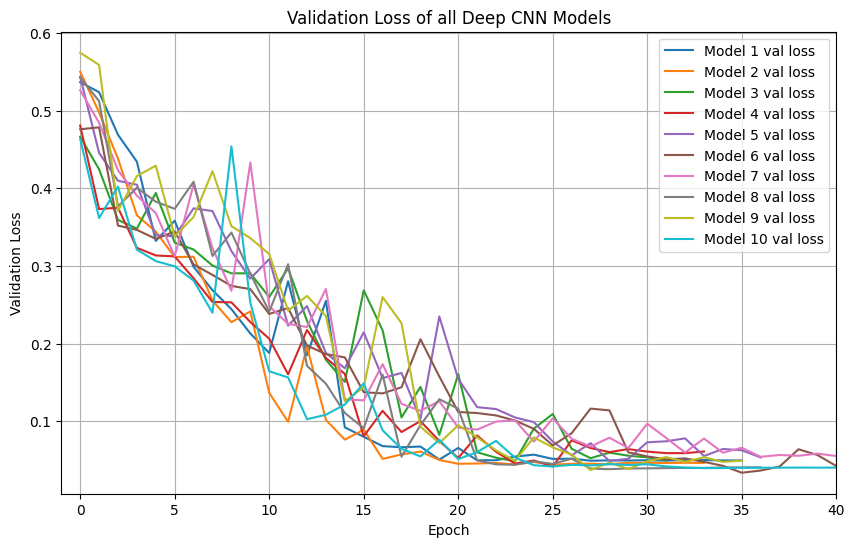

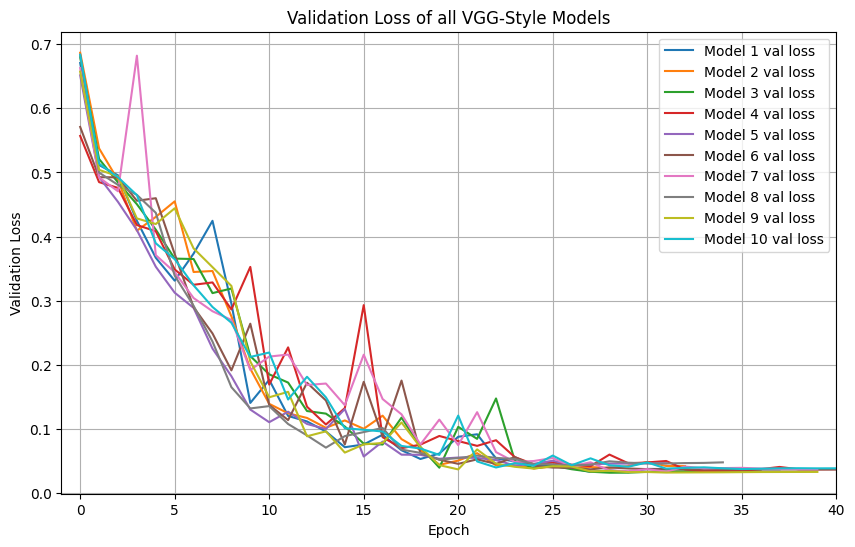

In [ ]:
plot_ensemble_val_loss(ensemble_histories_cnn, "Validation Loss of all Deep CNN Models")
plot_ensemble_val_loss(ensemble_histories_vgg, "Validation Loss of all VGG-Style Models")

## Confusion matrices

In [ ]:
weights_cnn = compute_model_weights(ensemble_models_cnn, X_val, y_val)
weights_vgg = compute_model_weights(ensemble_models_vgg, X_val, y_val)
weights_mix = compute_model_weights(ensemble_models_mix, X_val, y_val)

In [ ]:
final_probs_val_cnn, final_preds_val_cnn = ensemble_predict_weighted(ensemble_models_cnn, weights_cnn, X_val, 0.5)
final_probs_val_vgg, final_preds_val_vgg = ensemble_predict_weighted(ensemble_models_vgg, weights_vgg, X_val, 0.5)
final_probs_val_mix, final_preds_val_mix = ensemble_predict_weighted(ensemble_models_mix, weights_mix, X_val, 0.5)

In [ ]:
best_cnn_threshold, best_cnn_f1 = find_best_threshold_f1(y_val, final_probs_val_cnn)
best_vgg_threshold, best_vgg_f1 = find_best_threshold_f1(y_val, final_probs_val_vgg)
best_mix_threshold, best_mix_f1 = find_best_threshold_f1(y_val, final_probs_val_mix)

In [ ]:
final_probs_test_cnn, final_preds_test_cnn = ensemble_predict_weighted(ensemble_models_cnn, weights_cnn, X_test, best_cnn_threshold)
final_probs_test_vgg, final_preds_test_vgg = ensemble_predict_weighted(ensemble_models_vgg, weights_vgg, X_test, best_vgg_threshold)
final_probs_test_mix, final_preds_test_mix = ensemble_predict_weighted(ensemble_models_mix, weights_mix, X_test, best_mix_threshold)

In [ ]:
final_probs_val_cnn9 = model_cnn9.predict(X_val, verbose=0).ravel()
final_probs_test_cnn9 = model_cnn9.predict(X_test, verbose=0).ravel()
final_probs_val_vgg7 = model_vgg7.predict(X_val, verbose=0).ravel()
final_probs_test_vgg7 = model_vgg7.predict(X_test, verbose=0).ravel()
final_probs_val_fc = model_fc.predict(X_val, verbose=0).ravel()
final_probs_test_fc = model_fc.predict(X_test, verbose=0).ravel()
final_preds_val_cnn9 = (final_probs_val_cnn9 > 0.5).astype(int)
final_preds_test_cnn9 = (final_probs_test_cnn9 > 0.5).astype(int)
final_preds_val_vgg7 = (final_probs_val_vgg7 > 0.5).astype(int)
final_preds_test_vgg7 = (final_probs_test_vgg7 > 0.5).astype(int)
final_preds_val_fc = (final_probs_val_fc > 0.5).astype(int)
final_preds_test_fc = (final_probs_test_fc > 0.5).astype(int)

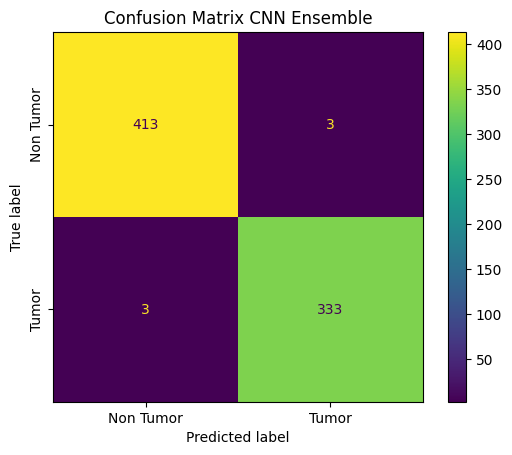

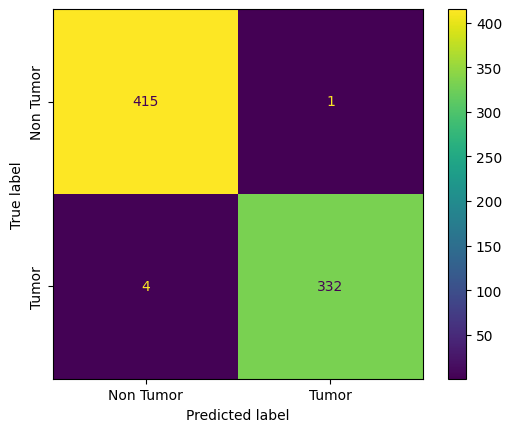

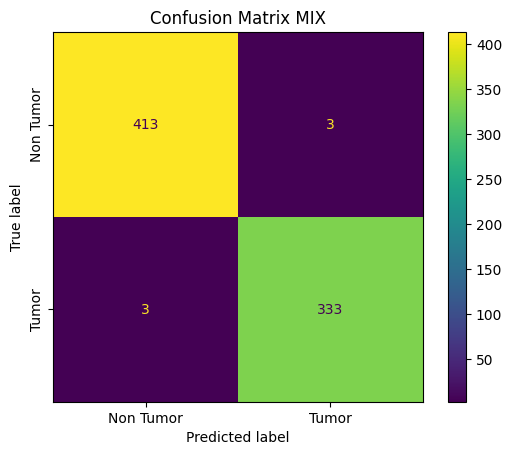

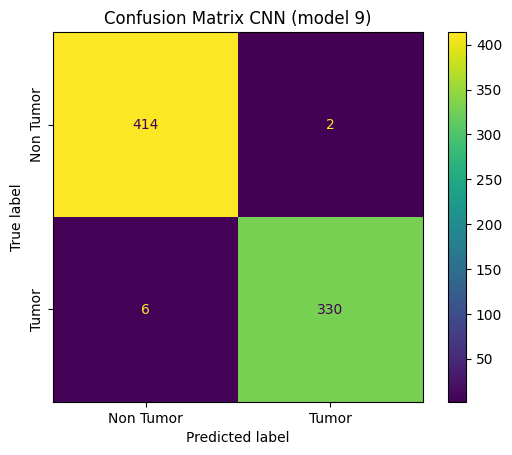

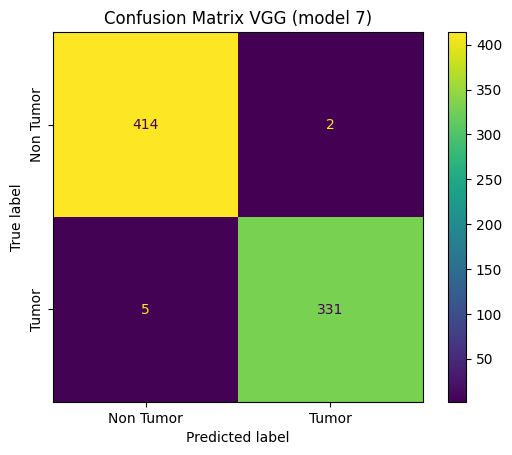

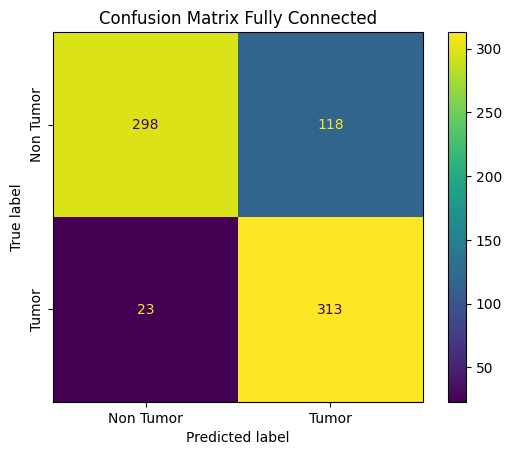

In [ ]:
plot_confusion_matrix(y_val, final_preds_val_cnn, title="Confusion Matrix CNN Ensemble")
plot_confusion_matrix(y_val, final_preds_val_vgg, title="Confusion Matrix VGG-Style Ensemble")
plot_confusion_matrix(y_val, final_preds_val_mix, title="Confusion Matrix MIX")
plot_confusion_matrix(y_val, final_preds_val_cnn9, title="Confusion Matrix CNN (model 9)")
plot_confusion_matrix(y_val, final_preds_val_vgg7, title="Confusion Matrix VGG (model 7)")
plot_confusion_matrix(y_val, final_preds_val_fc, title="Confusion Matrix Fully Connected")

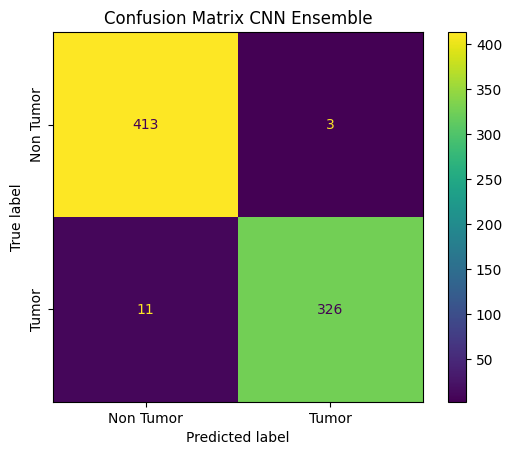

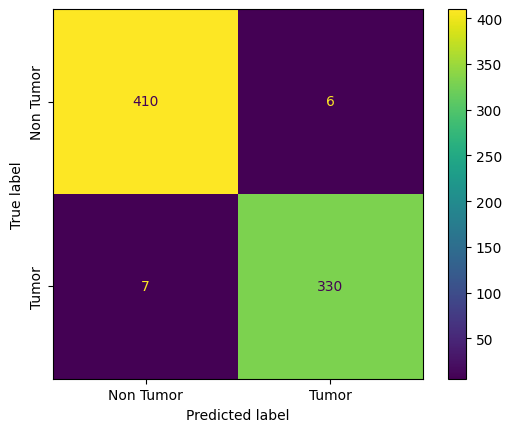

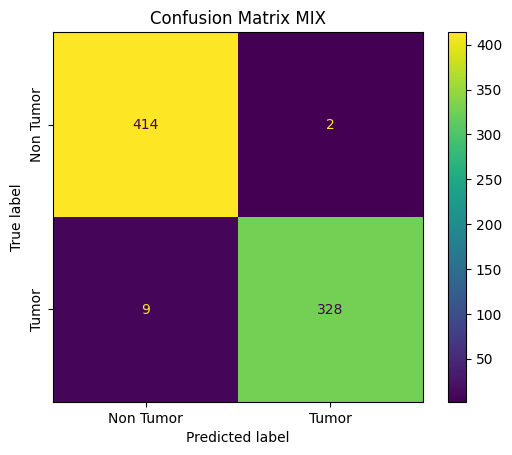

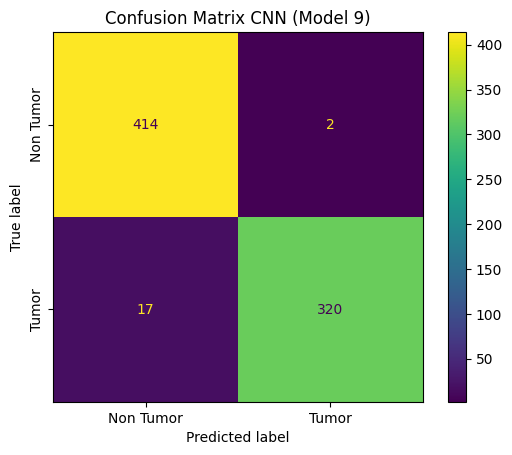

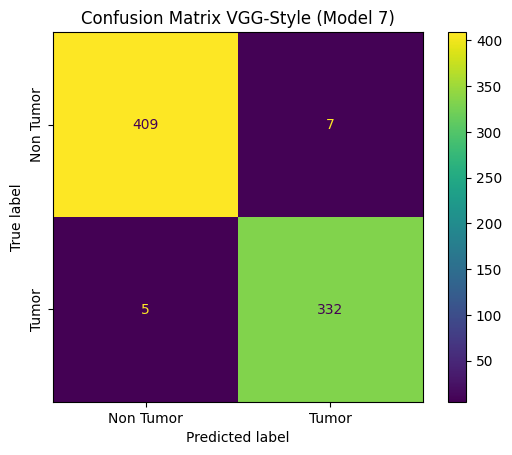

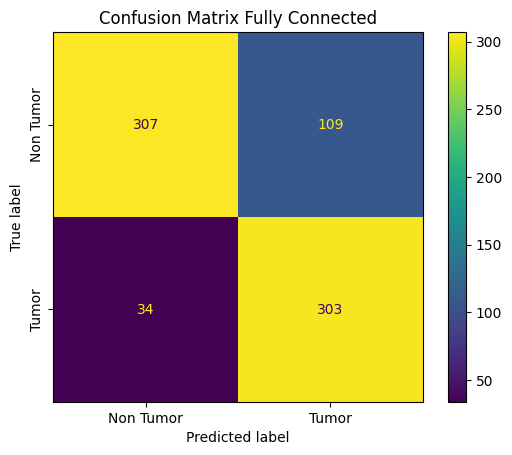

In [ ]:
plot_confusion_matrix(y_test, final_preds_test_cnn, title="Confusion Matrix CNN Ensemble")
plot_confusion_matrix(y_test, final_preds_test_vgg, title="Confusion Matrix VGG-Style Ensemble")
plot_confusion_matrix(y_test, final_preds_test_mix, title="Confusion Matrix MIX")
plot_confusion_matrix(y_test, final_preds_test_cnn9, title="Confusion Matrix CNN (Model 9)")
plot_confusion_matrix(y_test, final_preds_test_vgg7, title="Confusion Matrix VGG-Style (Model 7)")
plot_confusion_matrix(y_test, final_preds_test_fc, title="Confusion Matrix Fully Connected")

##ROC curves

In [ ]:
models_probs_val = create_models_probs_dict(
    final_probs_val_cnn,
    final_probs_val_vgg,
    final_probs_val_mix,
    final_probs_val_vgg7,
    final_probs_val_cnn9,
    final_probs_val_fc
)

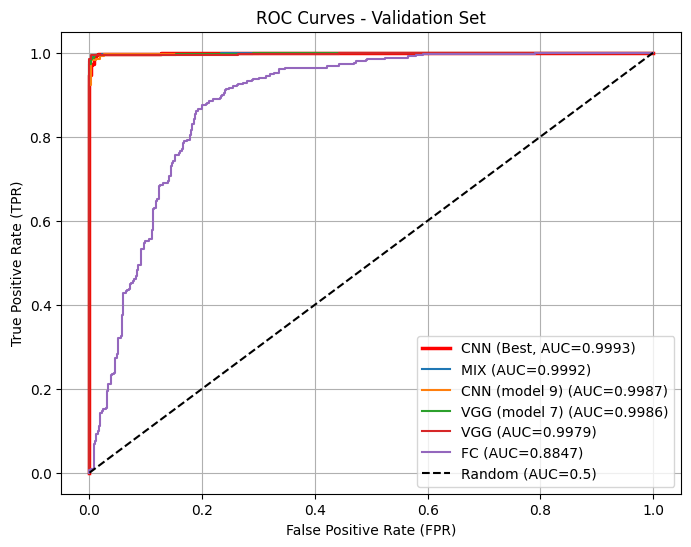

In [ ]:
plot_multiple_roc_curves(y_val, models_probs_val, 'ROC Curves - Validation Set')

In [ ]:
models_probs_test = create_models_probs_dict(
    final_probs_test_cnn,
    final_probs_test_vgg,
    final_probs_test_mix,
    final_probs_test_vgg7,
    final_probs_test_cnn9,
    final_probs_test_fc
)

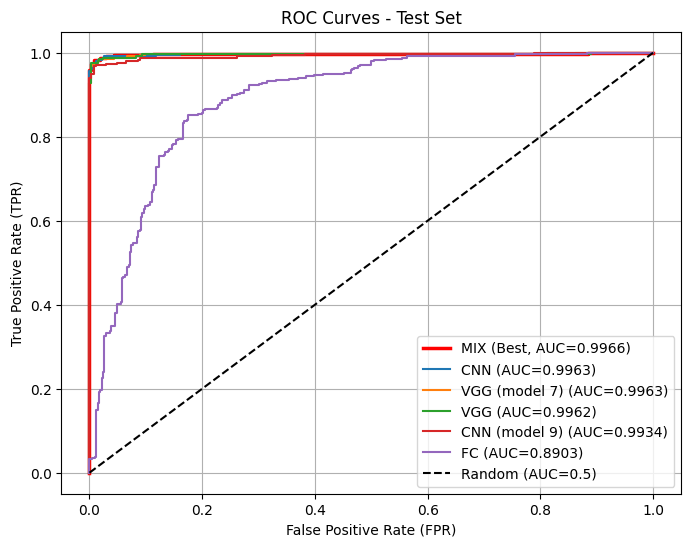

In [ ]:
plot_multiple_roc_curves(y_test, models_probs_test, 'ROC Curves - Test Set')

##PR curves

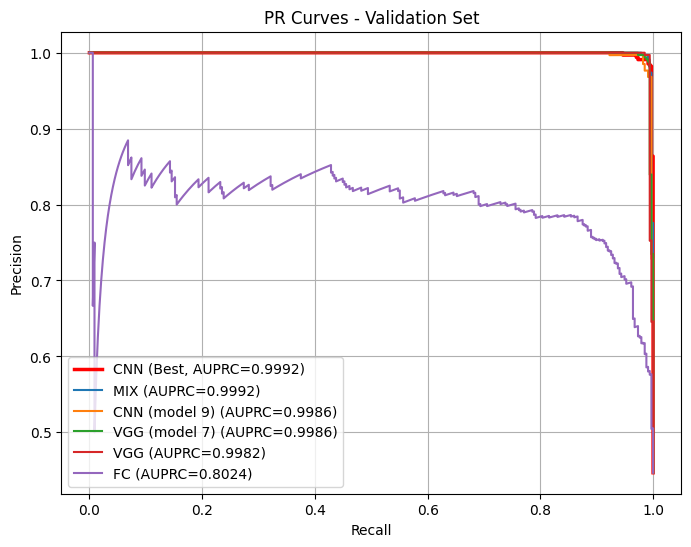

In [ ]:
plot_multiple_pr_curves(y_val, models_probs_val, 'PR Curves - Validation Set')

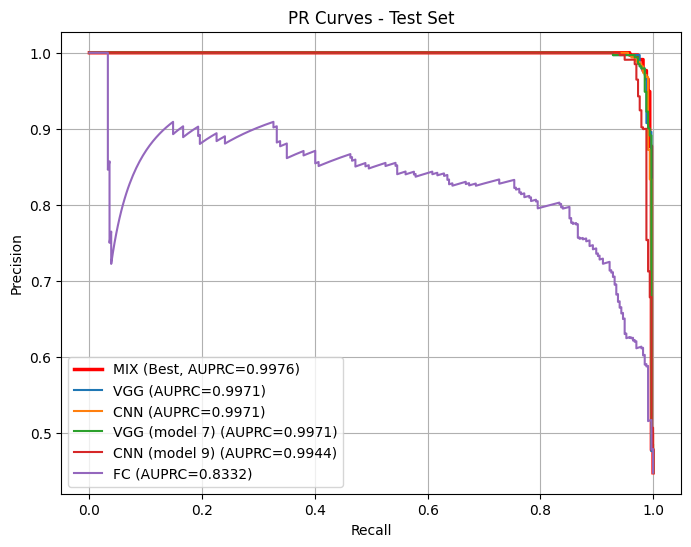

In [ ]:
plot_multiple_pr_curves(y_test, models_probs_test, 'PR Curves - Test Set')

# F1 Score

In [ ]:
print("F1 Score for Test Set")
print("CNN:", f1_score(y_test, final_preds_test_cnn))
print("VGG-Style:", f1_score(y_test, final_preds_test_vgg))
print("Mix:", f1_score(y_test, final_preds_test_mix))
print("CNN Model 9:", f1_score(y_test, final_preds_test_cnn9))
print("VGG Model 7:", f1_score(y_test, final_preds_test_vgg7))
print("Fully Connected:", f1_score(y_test, final_preds_test_fc))

F1 Score for Test Set
CNN: 0.978978978978979
VGG-Style: 0.9806835066864784
Mix: 0.9835082458770614
CNN Model 9: 0.9711684370257967
VGG Model 7: 0.9822485207100592
Fully Connected: 0.8090787716955942
